In [1]:
list.files(".")

[1] "01_tximport.ipynb" "AGENTS.md"         "README.md"        
 [4] "bin"               "data"              "main.nf"          
 [7] "metadata"          "modules"           "nextflow.config"  
[10] "results"

## Подготовка данных

In [2]:
# берем таблицу образцов
samples <- read.csv(
  "metadata/samplesheet.csv",
  stringsAsFactors = FALSE
)

samples

sample,run_accession,fastq_1,fastq_2
<chr>,<chr>,<chr>,<chr>
N3,SRR13344595,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_2.fastq.gz
N4,SRR13344596,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_2.fastq.gz
N5,SRR13344597,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_2.fastq.gz
N13,SRR13344598,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_2.fastq.gz
N17,SRR13344599,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_2.fastq.gz
N19,SRR13344600,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_2.fastq.gz
N21,SRR13344601,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_2.fastq.gz
N22,SRR13344602,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_2.fastq.gz
T3,SRR13344603,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_2.fastq.gz


In [3]:
# добавим пациента и тип ткани
samples$patient <- sub("^[NT]", "", samples$sample)

samples$condition <- ifelse(
  startsWith(samples$sample, "N"),
  "normal",
  "tumor"
)

samples[, c("sample", "patient", "condition")]

sample,patient,condition
<chr>,<chr>,<chr>
N3,3,normal
N4,4,normal
N5,5,normal
N13,13,normal
N17,17,normal
N19,19,normal
N21,21,normal
N22,22,normal
T3,3,tumor


In [4]:
# проверим пути к файлам Salmon
files <- file.path("results", "salmon", samples$sample, "quant.sf")
names(files) <- samples$sample

files
all(file.exists(files))

N3                            N4 
 "results/salmon/N3/quant.sf"  "results/salmon/N4/quant.sf" 
                           N5                           N13 
 "results/salmon/N5/quant.sf" "results/salmon/N13/quant.sf" 
                          N17                           N19 
"results/salmon/N17/quant.sf" "results/salmon/N19/quant.sf" 
                          N21                           N22 
"results/salmon/N21/quant.sf" "results/salmon/N22/quant.sf" 
                           T3                            T4 
 "results/salmon/T3/quant.sf"  "results/salmon/T4/quant.sf" 
                           T5                           T13 
 "results/salmon/T5/quant.sf" "results/salmon/T13/quant.sf" 
                          T17                           T19 
"results/salmon/T17/quant.sf" "results/salmon/T19/quant.sf" 
                          T21                           T22 
"results/salmon/T21/quant.sf" "results/salmon/T22/quant.sf"

[1] TRUE

In [5]:
# берем таблицу tx2gene
annotation <- read.delim(
  "data/reference/tx2gene_gencode50.tsv",
  stringsAsFactors = FALSE
)

tx2gene <- annotation[, c("transcript_id", "gene_id")]

head(tx2gene)

,transcript_id,gene_id
,<chr>,<chr>
1,ENST00000832824.1,ENSG00000290825.2
2,ENST00000832825.1,ENSG00000290825.2
3,ENST00000832826.1,ENSG00000290825.2
4,ENST00000832827.1,ENSG00000290825.2
5,ENST00000832828.1,ENSG00000290825.2
6,ENST00000832829.1,ENSG00000290825.2


In [6]:
# проверим, что каждый транскрипт встречается в таблице только один раз и нет пропусков
anyDuplicated(tx2gene$transcript_id)
anyNA(tx2gene)
any(tx2gene$transcript_id == "" | tx2gene$gene_id == "")
any(tx2gene$transcript_id == " " | tx2gene$gene_id == " ")

[1] 0

[1] FALSE

[1] FALSE

[1] FALSE

In [7]:
# запускаем расчет tximport

library(tximport)

txi <- tximport(
  files,
  type = "salmon",
  tx2gene = tx2gene,
  countsFromAbundance = "no"  # суммируем исходные оценки NumReads, а не пересчитываем количества из TPM
)

reading in files with read.delim (install 'readr' package for speed up)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [8]:
# смотрим на txi

names(txi)                                         # компоненты
dim(txi$counts)                                    # число генов и образцов
txi$counts[1:6, 1:4]                               # небольшой фрагмент матрицы
identical(colnames(txi$counts), samples$sample)    # совпадают ли имена и порядок образцов в матрице с таблицей метаданных; ожидаем TRUE

[1] "abundance"           "counts"              "length"             
[4] "countsFromAbundance"

[1] 78292    16

,N3,N4,N5,N13
ENSG00000000003.18,255.593,33.551,26.878,26.151
ENSG00000000005.7,0.000,0.000,0.000,0.000
ENSG00000000419.16,91.554,104.832,64.114,83.004
ENSG00000000457.16,105.955,52.975,64.579,66.067
ENSG00000000460.19,42.575,41.289,45.346,39.804
ENSG00000000938.15,17.951,44.018,28.038,85.014


[1] TRUE

In [9]:
# проверяем сходится ли TPM
colSums(txi$abundance)

N3    N4    N5   N13   N17   N19   N21   N22    T3    T4    T5   T13   T17 
1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 1e+06 
  T19   T21   T22 
1e+06 1e+06 1e+06

In [10]:
# обозначим пациента и ткань как категории (факторы)

samples$patient <- factor(samples$patient)

samples$condition <- factor(
  samples$condition,
  levels = c("normal", "tumor")
)

rownames(samples) <- samples$sample

samples

,sample,run_accession,fastq_1,fastq_2,patient,condition
,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
N3,N3,SRR13344595,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/095/SRR13344595/SRR13344595_2.fastq.gz,3,normal
N4,N4,SRR13344596,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/096/SRR13344596/SRR13344596_2.fastq.gz,4,normal
N5,N5,SRR13344597,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/097/SRR13344597/SRR13344597_2.fastq.gz,5,normal
N13,N13,SRR13344598,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/098/SRR13344598/SRR13344598_2.fastq.gz,13,normal
N17,N17,SRR13344599,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/099/SRR13344599/SRR13344599_2.fastq.gz,17,normal
N19,N19,SRR13344600,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/000/SRR13344600/SRR13344600_2.fastq.gz,19,normal
N21,N21,SRR13344601,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/001/SRR13344601/SRR13344601_2.fastq.gz,21,normal
N22,N22,SRR13344602,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/002/SRR13344602/SRR13344602_2.fastq.gz,22,normal
T3,T3,SRR13344603,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_1.fastq.gz,https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR133/003/SRR13344603/SRR13344603_2.fastq.gz,3,tumor


In [11]:
#  проверка на парность образцов
table(samples$patient, samples$condition)

    
     normal tumor
  13      1     1
  17      1     1
  19      1     1
  21      1     1
  22      1     1
  3       1     1
  4       1     1
  5       1     1

In [12]:
# объединяем результаты tximport, метаданные и задаем дизайн эксперимента в объект DESeq2

library(DESeq2)

stopifnot(
  identical(colnames(txi$counts), rownames(samples))
)

dds <- DESeqDataSetFromTximport(
  txi = txi,                       # результаты квантификации, суммированные по генам
  colData = samples,               # метаданные образцов
  design = ~ patient + condition   # формула, которая указывает, какие колонки метаданных использовать в модели в качестве факторов
)

dds

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    Filter, Find, Map, Position, Reduce, anyDuplicated, aperm, append,
    as.data.frame, basename, cbind, colnames, dirname, do.call,
    duplicated, eval, evalq, get, grep, grepl, is.unsorted, lapply,
    mapply, match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    rank, rbind, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

class: DESeqDataSet 
dim: 78292 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(78292): ENSG00000000003.18 ENSG00000000005.7 ...
  ENSG00000310795.1 ENSG00000310796.1
rowData names(0):
colnames(16): N3 N4 ... T21 T22
colData names(6): sample run_accession ... patient condition

In [13]:
# формула дизайна
design(dds)

~patient + condition

In [14]:
# правило для фильтрации
keep <- rowSums(counts(dds) >= 10) >= 8    # оставляем гены с ≥10 фрагментами хотя бы в 8 из 16 образцов:

table(keep)

keep
FALSE  TRUE 
61295 16997 

In [15]:
# фильтрация
dds_filtered <- dds[keep, ]

dim(dds_filtered)

[1] 16997    16

## Нормализация: поправки на различия библиотек и длины транскриптов

In [16]:
# рассчитываем нормировочные коэффициенты
dds_filtered <- estimateSizeFactors(dds_filtered)

using 'avgTxLength' from assays(dds), correcting for library size



In [17]:
# посмотреть фрагмент сохранённой матрицы поправок
normalizationFactors(dds_filtered)[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,1.0395933,1.1396911,1.3194889,0.8358717
ENSG00000000419.16,1.0132545,0.9878762,0.9238019,0.9319046
ENSG00000000457.16,0.9885598,1.1952114,1.0667879,0.8648978
ENSG00000000460.19,1.3304352,0.9042105,0.9397541,0.9041359
ENSG00000000938.15,0.9752313,1.0890277,0.9304232,1.1470799
ENSG00000000971.19,1.1008937,0.9662897,0.9711407,1.0141126


In [18]:
# получить матрицу нормализованных каунтов и посмотреть ее фрагмент
normalized_counts <- counts(dds_filtered, normalized = TRUE)
normalized_counts[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,246.25015,29.83265,20.46247,31.10525
ENSG00000000419.16,90.79654,106.28863,69.27892,89.06492
ENSG00000000457.16,107.22669,44.34362,60.93058,76.30959
ENSG00000000460.19,32.32025,45.34342,47.88487,44.24114
ENSG00000000938.15,18.45716,40.40301,30.09383,74.10120
ENSG00000000971.19,457.80988,1003.83972,894.82403,971.29256


## PCA

In [19]:
# Преобразовать значения с учётом дизайна при оценке дисперсии
vsd <- vst(dds_filtered, blind = FALSE)

In [20]:
# смотрим фрагмент преобразованных данных
assay(vsd)[1:6, 1:4]

,N3,N4,N5,N13
ENSG00000000003.18,7.979604,5.160215,4.716539,5.211028
ENSG00000000419.16,6.598300,6.812465,6.235454,6.572256
ENSG00000000457.16,6.824464,5.653840,6.065690,6.364350
ENSG00000000460.19,5.257904,5.682313,5.752241,5.650889
ENSG00000000938.15,4.600259,5.535753,5.170793,6.325093
ENSG00000000971.19,8.857929,9.980174,9.815395,9.932919


In [61]:
options(
  repr.plot.width = 12,
  repr.plot.height = 8
)

using ntop=500 top features by variance



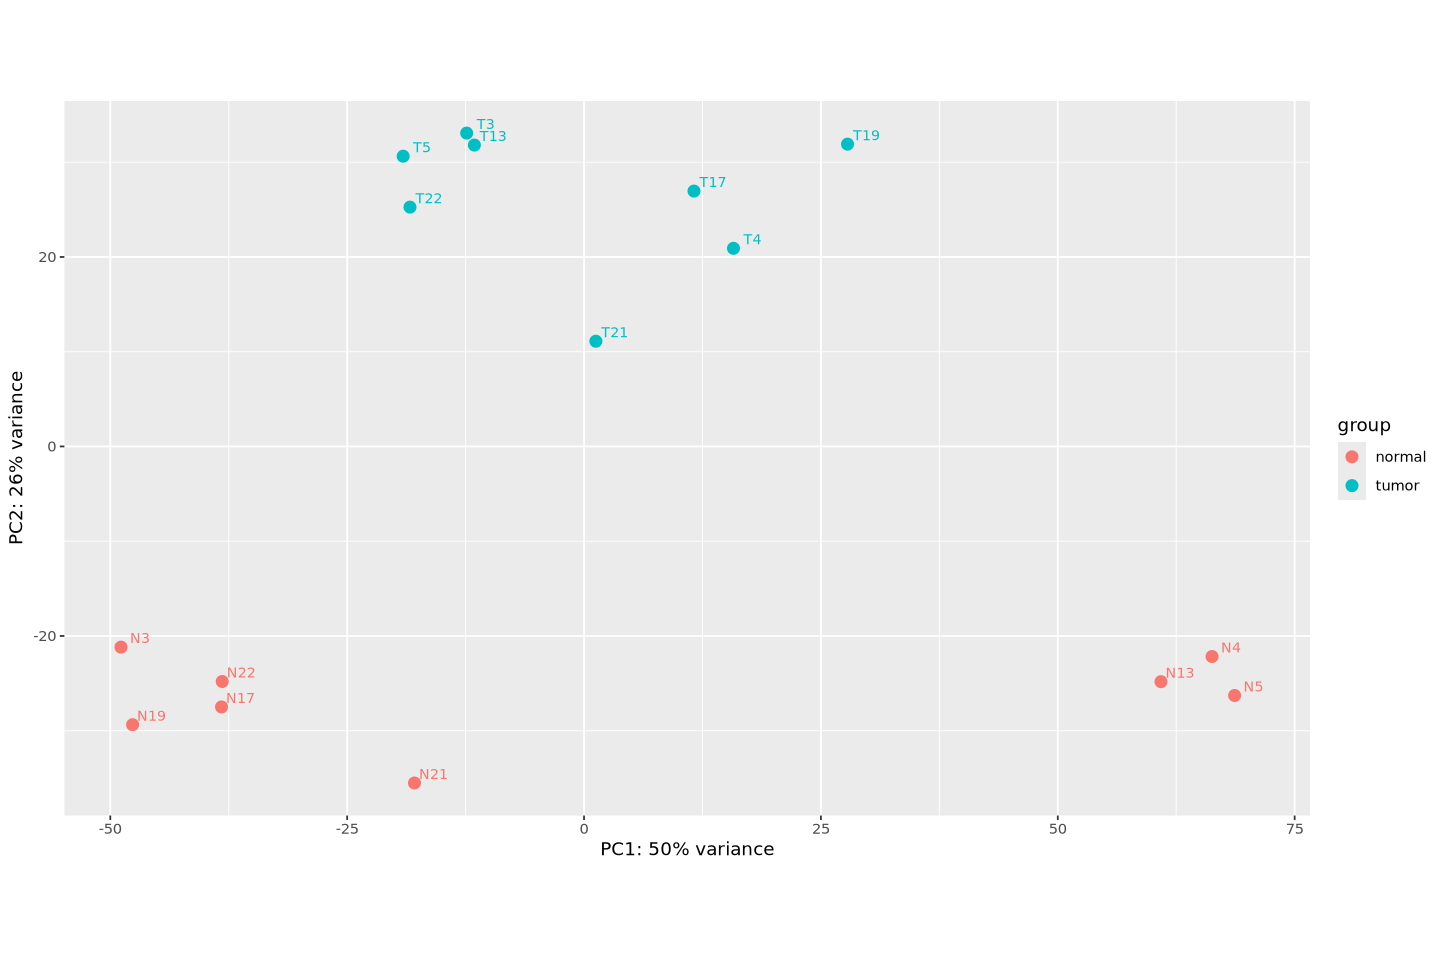

In [63]:
# расчет PCA + график с подписями
plotPCA(vsd, intgroup = "condition", ntop = 500) +
  ggplot2::geom_text(
    ggplot2::aes(label = name),
    nudge_x = 2,        # сдвиг вправо в единицах оси PC1
    vjust = -0.4,
    size = 3,
    show.legend = FALSE
  )